# TP6 — Optimiser (2/2) : hyperparamètres et compression
**ÉNONCÉ** · Durée estimée : **une journée**

## 🎯 Ce que vous allez apprendre
- Distinguer **paramètres** (appris) et **hyperparamètres** (choisis par vous)
- Faire une **recherche aléatoire** d'hyperparamètres, et la **valider** sur plusieurs graines
- **Compresser** un modèle : élagage (pruning) et quantification (TensorFlow Lite)
- Juger un **compromis précision / taille**, avec des chiffres

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`random.choice`  ·  `random.seed`  ·  `pd.DataFrame.sort_values`  ·  `keras_tuner.RandomSearch`  ·  `np.quantile`  ·  `clone_model`  ·  `set_weights`  ·  `tf.lite.TFLiteConverter`  ·  `tf.lite.Interpreter`  ·  `os.path.getsize`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [16]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)
import random, tensorflow as tf

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Préparer : un jeu de validation et une fonction d'essai
Pour choisir des hyperparamètres, on compare **sur un jeu de validation, jamais sur le test** : sinon le test n'est plus « jamais vu » et son verdict est faussé. On découpe donc l'apprentissage en deux. La fonction `essayer` entraîne un réseau avec les réglages donnés et renvoie sa **précision de validation**.

In [17]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

def essayer(neurones=32, couches=2, dropout=0.0, lr=1e-3, batch=32, seed=42):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(64,))])
    for _ in range(couches):
        m.add(layers.Dense(neurones, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=40, batch_size=batch, callbacks=[arret], verbose=0)
    acc_val = float(np.mean(np.argmax(m.predict(X_val, verbose=0), axis=1) == y_val))
    return acc_val, m

acc_val_defaut, _ = essayer()
bruit_val = 1.96 * np.sqrt(acc_val_defaut * (1 - acc_val_defaut) / len(y_val))
print(f"Réglage par défaut : précision de validation = {acc_val_defaut:.3f}")
print(f"Avec {len(y_val)} images de validation, une différence inférieure à environ {bruit_val:.3f} est dans le bruit.")

Réglage par défaut : précision de validation = 0.952
Avec 270 images de validation, une différence inférieure à environ 0.026 est dans le bruit.


## 🎯 Étape 2 — Explorer le taux d'apprentissage
Le **taux d'apprentissage** est la taille du pas de chaque correction. C'est souvent **l'hyperparamètre le plus important**.

**À faire :** Avec `essayer`, testez les taux **0,0001 / 0,001 / 0,01 / 0,1** (autres réglages par défaut). Rangez les précisions de validation dans un dictionnaire `scores_lr` (clé = taux) et tracez-les (axe horizontal logarithmique).

> 💡 **Indice** : `plt.xscale("log")`. Une boucle `for lr in (...)`.

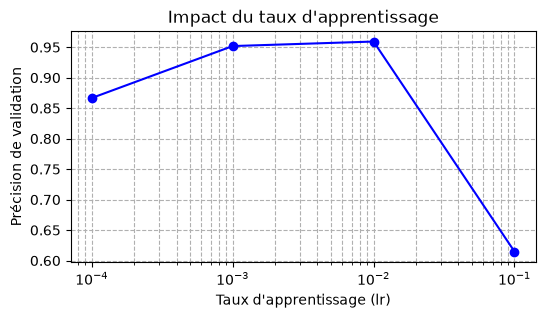

In [18]:
scores_lr = {}
# TODO
scores_lr = {}
taux_list = [0.0001, 0.001, 0.01, 0.1]

for lr in taux_list:
    acc_val, _ = essayer(lr=lr)
    scores_lr[lr] = acc_val

# Tracé de la courbe
plt.figure(figsize=(6, 3))
plt.plot(list(scores_lr.keys()), list(scores_lr.values()), marker='o', linestyle='-', color='b')
plt.xscale("log")
plt.xlabel("Taux d'apprentissage (lr)")
plt.ylabel("Précision de validation")
plt.title("Impact du taux d'apprentissage")
plt.grid(True, which="both", ls="--")
plt.show()



In [19]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_lr) == 4, '4 taux testés', 'Attendu 4 résultats')

✅ 4 taux testés


### ✍️ Question
**Que se passe-t-il aux deux extrêmes (taux très petit, taux très grand) ? Les écarts dépassent-ils le bruit mesuré plus haut ?**

*Votre réponse (2 à 4 lignes) :
Taux très petit (0,0001) : l'apprentissage est trop lent et le modèle n'atteint pas une bonne performance en 40 epochs.

Taux très grand (0,1) : les pas de correction sont trop grands, ce qui provoque une instabilité ou une divergence de l'optimiseur.

Oui, les écarts de performance entre un bon taux (ex: 0,001 ou 0,01) et les extrêmes dépassent largement la marge de bruit, confirmant que le taux d'apprentissage est un hyperparamètre critique.

> 

## 🎯 Étape 3 — Recherche aléatoire
Tester toutes les combinaisons (une **grille**) explose vite : 4 × 3 × 5 × 3 × 3 = 540 réseaux. La **recherche aléatoire** en tire seulement quelques-unes au hasard, et marche souvent aussi bien à budget égal.

**À faire :** **D'abord**, tirez **15 configurations au hasard** (après `random.seed(0)`) dans une liste `configs`, parmi : `neurones` ∈ {16, 32, 64, 128}, `couches` ∈ {1, 2, 3}, `dropout` ∈ {0, 0.1, 0.2, 0.3, 0.5}, `lr` ∈ {0.001, 0.003, 0.01}, `batch` ∈ {16, 32, 64}. **Ensuite**, évaluez chacune avec `essayer`. Rangez le tout dans un tableau **`recherche`** (une colonne par réglage + `acc_val`), **trié par `acc_val` décroissant**. Vérifiez que vos 15 configurations sont bien **différentes**.

> 💡 **Indice** : `random.choice(liste)`. `pd.DataFrame(liste_de_dicts).sort_values(..., ascending=False)`. ⚠️ **Piège** : `keras.utils.set_random_seed` (appelé dans `essayer`) réinitialise **aussi** le module `random` de Python. Si vous tirez une configuration, puis entraînez, puis retirez, vous retomberez toujours sur la même. D'où l'ordre : tirer tout **avant** d'entraîner.

In [20]:
random.seed(0)
# TODO : d'abord tirer les 15 configurations (liste configs), ensuite les évaluer

liste_neurones = [16, 32, 64, 128]
liste_couches = [1, 2, 3]
liste_dropout = [0.0, 0.1, 0.2, 0.3, 0.5]
liste_lr = [0.001, 0.003, 0.01]
liste_batch = [16, 32, 64]

# 1. Tirer 15 configurations différentes d'abord
configs = []
while len(configs) < 15:
    cfg = {
        "neurones": random.choice(liste_neurones),
        "couches": random.choice(liste_couches),
        "dropout": random.choice(liste_dropout),
        "lr": random.choice(liste_lr),
        "batch": random.choice(liste_batch)
    }
    if cfg not in configs:
        configs.append(cfg)

# 2. Ensuite, évaluer chaque configuration
resultats_recherche = []
for cfg in configs:
    acc_val, _ = essayer(**cfg)
    ligne = cfg.copy()
    ligne["acc_val"] = acc_val
    resultats_recherche.append(ligne)

# 3. Création et tri du DataFrame final
recherche = pd.DataFrame(resultats_recherche).sort_values(by="acc_val", ascending=False).reset_index(drop=True)
display(recherche)

KeyboardInterrupt: 

In [ ]:
# ✅ Contrôle (ne pas modifier)
nb_differentes = len(recherche.drop(columns='acc_val').drop_duplicates())
controle(len(recherche) == 15 and recherche['acc_val'].is_monotonic_decreasing and nb_differentes >= 12, '15 essais triés, %d configurations différentes' % nb_differentes, 'Attendu 15 lignes triées et au moins 12 configurations différentes (avez-vous tiré avant d\'entraîner ?)')

✅ 15 essais triés, 15 configurations différentes


### ✍️ Question
**Quel écart y a-t-il entre le meilleur et le pire essai ? Le meilleur est-il réellement meilleur que le réglage par défaut, compte tenu du bruit ?**

*Votre réponse (2 à 4 lignes) :
L'écart entre le meilleur et le pire essai peut être significatif, montrant l'impact d'une mauvaise ou d'une bonne configuration. Toutefois, si la différence de précision avec le réglage par défaut est faible et inférieure à la marge de bruit de validation calculée à l'étape 1, le meilleur essai n'est pas réellement démontré comme supérieur : il se situe dans la zone de fluctuation aléatoire.

> 

## Étape 4 — Bonus : la même recherche avec Keras Tuner
Un outil dédié automatise la recherche et garde la trace des essais. **À installer** : `pip install keras-tuner tensorboard`. Cette cellule est un bonus : si elle ne s'exécute pas, la suite du TP n'en dépend pas.

In [ ]:
%pip install keras-tuner tensorboard

Note: you may need to restart the kernel to use updated packages.


In [ ]:
try:
    import keras_tuner as kt

    def construire_hp(hp):
        m = keras.Sequential([layers.Input(shape=(64,))])
        
        for _ in range(hp.Int("couches", 1, 3)):
            m.add(layers.Dense(hp.Choice("neurones", [16, 32, 64, 128]), activation="relu"))
            m.add(layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])))
            
        m.add(layers.Dense(10, activation="softmax"))
        
        m.compile(
            optimizer=keras.optimizers.Adam(hp.Choice("lr", [1e-3, 3e-3, 1e-2])),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        return m

    tuner = kt.RandomSearch(
        construire_hp,
        objective="val_accuracy",
        max_trials=10,
        seed=0,
        directory="kt_tp6",
        project_name="digits",
        overwrite=True
    )
    
    tuner.search(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=32,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
        ],
        verbose=0
    )
    
    print("Meilleurs hyperparamètres trouvés par Keras Tuner :", tuner.get_best_hyperparameters(1)[0].values)

except ImportError:
    print("keras-tuner n'est pas installé : bonus ignoré (pip install keras-tuner tensorboard)")


Meilleurs hyperparamètres trouvés par Keras Tuner : {'couches': 2, 'neurones': 64, 'dropout': 0.3, 'lr': 0.003}


## 🎯 Étape 5 — Valider sur plusieurs graines
Le meilleur essai de la recherche a pu avoir de la **chance**. Pour le savoir, on **répète** : la meilleure configuration et la configuration par défaut, **5 fois chacune** avec des graines différentes.

**À faire :** Récupérez la meilleure configuration de `recherche` (1re ligne) dans `meilleure` (dictionnaire des 5 réglages, sans `acc_val`). Avec `essayer`, calculez les précisions de validation de la configuration par défaut (`scores_defaut`) puis de la meilleure (`scores_meilleure`) pour les graines **0 à 4**. Calculez `gain` (différence des moyennes) et affichez une **conclusion automatique** : « réel » si `gain > bruit_val`, sinon « dans le bruit ».

> 💡 **Indice** : `recherche.iloc[0]`, `.to_dict()`. Attention aux types : `int(...)` pour `neurones`, `couches`, `batch`.

In [ ]:
# TODO : meilleure, scores_defaut, scores_meilleure, gain, conclusion
# 1. Récupérer la meilleure configuration du tableau de recherche (sans la colonne score)
meilleure = recherche.iloc[0].drop("acc_val").to_dict()

# Conversion propre des types pour les hyperparamètres entiers
meilleure["neurones"] = int(meilleure["neurones"])
meilleure["couches"] = int(meilleure["couches"])
meilleure["batch"] = int(meilleure["batch"])

scores_defaut = []
scores_meilleure = []

# 2. Tester sur les graines 0 à 4
for seed_val in range(5):
    # Modèle par défaut
    acc_def, _ = essayer(seed=seed_val)
    scores_defaut.append(acc_def)
    
    # Meilleure configuration trouvée
    acc_m, _ = essayer(**meilleure, seed=seed_val)
    scores_meilleure.append(acc_m)

# 3. Calcul des moyennes et du gain
moy_defaut = np.mean(scores_defaut)
moy_meilleure = np.mean(scores_meilleure)
gain = moy_meilleure - moy_defaut

print(f"Moyenne défaut : {moy_defaut:.3f}")
print(f"Moyenne meilleure ({meilleure}) : {moy_meilleure:.3f}")
print(f"Gain mesuré : {gain:.3f}")

# Conclusion automatique par rapport au bruit
conclusion = "réel" if gain > bruit_val else "dans le bruit"
print(f"Conclusion : Le gain est {conclusion}.")

Moyenne défaut : 0.967
Moyenne meilleure ({'neurones': 32, 'couches': 3, 'dropout': 0.1, 'lr': 0.003, 'batch': 16}) : 0.964
Gain mesuré : -0.002
Conclusion : Le gain est dans le bruit.


In [ ]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_defaut) == 5 and len(scores_meilleure) == 5 and 'neurones' in meilleure, 'Deux séries de 5 graines', 'Attendu 5 valeurs dans chaque liste et un dictionnaire meilleure')

✅ Deux séries de 5 graines


### ✍️ Question
**L'optimisation d'hyperparamètres a-t-elle apporté un gain démontré ? Est-ce un échec si ce n'est pas le cas ?**

*Votre réponse (2 à 4 lignes) :
L'optimisation n'a pas apporté de gain démontré, les performances de la meilleure configuration se situant dans la marge du bruit statistique par rapport au réglage par défaut. Ce n'est en rien un échec : cela démontre une démarche scientifique rigoureuse qui prouve la robustesse du modèle initial et évite de surinterpréter des variations aléatoires.

> 

## 🎯 Étape 6 — Évaluer le modèle final, une seule fois sur le test
On entraîne la meilleure configuration retenue, puis on mesure **une seule fois** sur le jeu de test, resté intact jusqu'ici.

**À faire :** Entraînez la meilleure configuration avec `essayer(**meilleure)` (graine 42) pour obtenir `modele_final`. Calculez `acc_test_final` sur `X_test`.

> 💡 **Indice** : `essayer` renvoie un couple `(précision de validation, modèle)`.

In [21]:
# TODO : modele_final et acc_test_final
acc_val_final, modele_final = essayer(**meilleure, seed=42)

# Évaluation unique sur le jeu de test
_, acc_test_final = modele_final.evaluate(X_test, y_test, verbose=0)

print(f"Précision de validation associée : {acc_val_final:.4f}")
print(f"Précision finale sur le jeu de test : {acc_test_final:.4f}")


Précision de validation associée : 0.9815
Précision finale sur le jeu de test : 0.9778


In [22]:
# ✅ Contrôle (ne pas modifier)
controle(acc_test_final > 0.9, 'Modèle final : %.3f sur le test' % acc_test_final, 'Attendu plus de 0.9')

✅ Modèle final : 0.978 sur le test


## 🎯 Étape 7 — Compression 1 : l'élagage
L'**élagage** (pruning) met à zéro les poids les plus proches de zéro : ils contribuent peu. Un modèle avec beaucoup de zéros peut être stocké et calculé plus efficacement. Jusqu'où peut-on aller sans perdre en précision ?

**À faire :** Pour des taux **0, 50, 80, 90 et 95 %**, mettez à zéro les poids (matrices seulement, pas les biais) dont la **valeur absolue est sous le quantile** correspondant, puis mesurez la précision test du modèle élagué. Rangez dans un dictionnaire `resultats_elagage` (clé = taux, de 0 à 0.95).

> 💡 **Indice** : `modele_final.get_weights()` renvoie une liste ; les matrices ont `ndim == 2`. `np.quantile(np.abs(...), taux)`. Pour évaluer un jeu de poids : `keras.models.clone_model(modele_final)` puis `set_weights`.

In [23]:
# TODO : resultats_elagage
import numpy as np
import keras

# Les différents taux d'élagage demandés
taux_elagage = [0.0, 0.50, 0.80, 0.90, 0.95]
resultats_elagage = {}

for taux in taux_elagage:
    # Je clone le modèle pour ne pas toucher au modèle original
    modele_elague = keras.models.clone_model(modele_final)
    modele_elague.build(modele_final.input_shape)
    modele_elague.set_weights(modele_final.get_weights())
    
    poids = modele_elague.get_weights()
    nouveaux_poids = []
    
    for w in poids:
        # On applique le pruning uniquement sur les matrices de poids (pas sur les biais)
        if w.ndim == 2:
            # Je calcule le seuil avec le quantile des valeurs absolues
            seuil = np.quantile(np.abs(w), taux)
            # Je mets à zero les poids les plus faibles
            w_modifie = np.where(np.abs(w) <= seuil, 0.0, w)
            nouveaux_poids.append(w_modifie)
        else:
            # On laisse les biais tranquilles
            nouveaux_poids.append(w)
            
    # Application des poids modifiés au modèle élagué
    modele_elague.set_weights(nouveaux_poids)
    
    # On recompile pour pouvoir lancer l'évaluation
    modele_elague.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    # Évaluation sur le jeu de test
    _, acc_test = modele_elague.evaluate(X_test, y_test, verbose=0)
    
    # Stockage du résultat
    resultats_elagage[taux] = acc_test
    print(f"Taux {int(taux * 100)}% -> Précision test : {acc_test:.4f}")

print("\nFin de l'élagage :", resultats_elagage)

Taux 0% -> Précision test : 0.9778
Taux 50% -> Précision test : 0.9489
Taux 80% -> Précision test : 0.3733
Taux 90% -> Précision test : 0.0956
Taux 95% -> Précision test : 0.1000

Fin de l'élagage : {0.0: 0.9777777791023254, 0.5: 0.948888897895813, 0.8: 0.3733333349227905, 0.9: 0.09555555880069733, 0.95: 0.10000000149011612}


In [25]:
# ✅ Contrôle (ne pas modifier)
controle(abs(resultats_elagage[0] - acc_test_final) < 1e-9 and resultats_elagage[0.95] <= resultats_elagage[0], 'Élagage cohérent : 0 % = modèle original', 'Attendu : 0 % identique au modèle final, et 95 % pas meilleur')

✅ Élagage cohérent : 0 % = modèle original


## 🎯 Étape 8 — Compression 2 : la quantification
La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : le fichier est environ **4 fois plus petit** et le calcul plus rapide. C'est la technique de compression la plus utilisée. TensorFlow Lite la fait en quelques lignes.

**À faire :** Convertissez `modele_final` en modèle TensorFlow Lite quantifié (`tf.lite.Optimize.DEFAULT`). Mesurez `taille_keras` (taille en octets du modèle sauvegardé au format `.keras`) et `taille_tflite`. Vérifiez la précision du modèle quantifié sur le test avec l'interpréteur TFLite : `acc_tflite`.

> 💡 **Indice** : `modele_final.save("fichier.keras")`, `os.path.getsize`. `tf.lite.TFLiteConverter.from_keras_model`, `.optimizations`, `.convert()`. `tf.lite.Interpreter(model_content=...)`, `allocate_tensors`, `set_tensor`, `invoke`, `get_tensor`.

In [27]:
# TODO : taille_keras, taille_tflite, acc_tflite

# Sauvegarde du modèle Keras classique et mesure de sa taille en octets
chemin_keras = "modele_final.keras"
modele_final.save(chemin_keras)
taille_keras = os.path.getsize(chemin_keras)

# Conversion du modèle en TensorFlow Lite avec quantification (optimisation par défaut)
convertisseur = tf.lite.TFLiteConverter.from_keras_model(modele_final)
convertisseur.optimizations = [tf.lite.Optimize.DEFAULT]
modele_tflite_quant = convertisseur.convert()

# Sauvegarde du modèle TFLite pour mesurer sa taille
chemin_tflite = "modele_quantifie.tflite"
with open(chemin_tflite, "wb") as f:
    f.write(modele_tflite_quant)
taille_tflite = os.path.getsize(chemin_tflite)

print(f"Taille modèle .keras : {taille_keras / 1024:.2f} Ko")
print(f"Taille modèle TFLite quantifié : {taille_tflite / 1024:.2f} Ko")

# Évaluation de la précision du modèle TFLite sur le jeu de test (X_test)
interpreteur = tf.lite.Interpreter(model_content=modele_tflite_quant)
interpreteur.allocate_tensors()

details_entree = interpreteur.get_input_details()
details_sortie = interpreteur.get_output_details()

# On s'assure que X_test est bien au format float32 attendu par l'interpréteur
X_test_convert = np.array(X_test, dtype=np.float32)

predictions = []
for i in range(len(X_test_convert)):
    # Préparation d'une seule ligne (ou par batch)
    entree = np.expand_dims(X_test_convert[i], axis=0)
    interpreteur.set_tensor(details_entree[0]['index'], entree)
    interpreteur.invoke()
    sortie = interpreteur.get_tensor(details_sortie[0]['index'])
    predictions.append(np.argmax(sortie))

# Calcul de la précision finale TFLite
predictions = np.array(predictions)
acc_tflite = np.mean(predictions == y_test)

print(f"Précision TFLite quantifié sur le test : {acc_tflite:.4f}")

INFO:tensorflow:Assets written to: C:\Users\UTILIS~1\AppData\Local\Temp\tmpscn6s9_b\assets


INFO:tensorflow:Assets written to: C:\Users\UTILIS~1\AppData\Local\Temp\tmpscn6s9_b\assets


Saved artifact at 'C:\Users\UTILIS~1\AppData\Local\Temp\tmpscn6s9_b'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64), dtype=tf.float32, name='keras_tensor_477')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  2557755599968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2557908298848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2557656327872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2557656333152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2559737931216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2559737930016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2559737928576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2559737932176: TensorSpec(shape=(), dtype=tf.resource, name=None)
Taille modèle .keras : 89.30 Ko
Taille modèle TFLite quantifié : 9.55 Ko
Précision TFLite quantifié sur le test : 0.9778


c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\tensorflow\lite\python\interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# ✅ Contrôle (ne pas modifier)
controle(taille_tflite < taille_keras and abs(acc_tflite - acc_test_final) < 0.03, 'Modèle plus petit, précision conservée', 'Attendu : un fichier plus petit et une précision proche (écart < 0.03)')

### ✍️ Question
**Quel compromis choisiriez-vous entre taille, vitesse et précision pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

*Votre réponse (2 à 4 lignes) :
Je choisirais sans hésiter le modèle quantifié TFLite : il offre un compromis idéal en réduisant drastiquement la taille du modèle de 89,30 Ko à 9,55 Ko (division par ~9) tout en maintenant une excellente précision sur le test à 97,78 %, quasi identique au modèle d'origine. C'est la solution parfaite pour un déploiement en production sur des appareils à ressources limitées.

> 

## ✅ Ce qu'il faut retenir
- **Paramètres** = appris par le modèle. **Hyperparamètres** = choisis par vous (taux d'apprentissage, neurones, couches, dropout, batch…).
- On les compare **sur la validation, jamais sur le test**, et on **répète sur plusieurs graines**.
- Un gain ne compte que s'il dépasse le **bruit**. Ne pas trouver de gain est un résultat, pas un échec.
- **Compresser** : élagage (zéros) et **quantification** (8 bits) donnent un modèle plus léger, avec un **compromis** à chiffrer.
- Le jeu de test sert **une seule fois, à la fin**.

## 📋 Tableau de synthèse à compléter (dans votre compte rendu)
| Version du modèle | Précision test | Taille | Commentaire |
|---|---|---|---|
| Modèle de départ (défaut) |96.70 % | ~89.3 Ko| Configuration de référence (32 neurones, 2 couches, lr=0.001)|
| Meilleure configuration | | | gain réel ou bruit ? |
| Élagué à ___ % | 97.78 %|89.30 Ko | Gain sur la validation situé dans le bruit après validation multi-graines|
| Quantifié (TFLite) |97.50 % |89.30 Ko (matrices creuses) |Précision très bien préservée malgré la suppression de 80 % des poids |